# **APS 2 — Inteligência Artificial Aplicada: Canteiro de Obras Inteligente "Torre Europarque"**
### *Sistemas Inteligentes de Otimização, Conhecimento, Redes Neurais e Lógica Fuzzy na Construção Civil*

* **Instituição:** Centro Universitário UniSENAI PR — Campus Londrina
* **Curso:** Engenharia de Software | 6º Período (2026/2)
* **Disciplina:** Inteligência Artificial Aplicada
* **Docente:** Prof. Paulo Cesar Dias Lima

**Integrantes do Grupo:**

* Felipy Yuske Ogido — RA: `[inserir RA]`
* Fernando Junior Vaciski de Camargo — RA: `[inserir RA]`
* Giovana Nunes Constancio Donato — RA: `01033251`
* Graciele Miki Sazaka — RA: `[inserir RA]`
* João Paulo Simplicio — RA: `[inserir RA]`

*(Representante do Grupo: `A DEFINIR`)*


In [1]:
# ==============================================================================
# CONFIGURAÇÃO DO AMBIENTE E IMPORTS GLOBAIS (TODAS AS ETAPAS)
# ==============================================================================

# Instalação das bibliotecas necessárias no Google Colab
# (PuLP fixado na série 2.x: a versão 4.x mudou a API e quebra pulp.LpVariable(lowBound=...))
!pip install -q "pulp<3" deap simpy rdflib scikit-fuzzy tabulate

# Base, manipulação de dados e visualização
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Etapa 1 — Busca Heurística (A*) e Programação Linear
import networkx as nx
import pulp

# Etapa 2 — Algoritmo Genético (VRP) e Simulação Discreta
from deap import base, creator, tools, algorithms
import simpy

# Etapa 3 — Ontologia RDF/OWL e SPARQL
from rdflib import Graph, Namespace, Literal, URIRef
from rdflib.namespace import RDF, RDFS, OWL, XSD

# Etapa 5 — Lógica Fuzzy
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Configurações globais de gráficos e pastas de saída
os.makedirs("outputs/graficos", exist_ok=True)
os.makedirs("outputs/tabelas", exist_ok=True)
plt.rcParams["figure.dpi"] = 120

# Semente global para reprodutibilidade (GA, SimPy, MLP)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


## Etapa 1 — Roteirização (A* em NetworkX) e Alocação de Recursos (PuLP)

### 1a — Busca Heurística A* (Malha 8x8)
O canteiro é modelado como uma malha ortogonal 8x8 (`nx.grid_2d_graph`), com movimentos em 4 direções e custo unitário por passo. Os obstáculos rígidos (andaimes e escavação) em **(3,3)** e **(3,4)** são removidos do grafo. O AGV parte do **Almoxarifado Central (0,0)** até a **Torre de Elevação (7,7)**, e o A* usa a **distância de Manhattan** como heurística h(n), que é admissível nesse tipo de malha (nunca superestima o custo real).

Origem (Almoxarifado Central): (0, 0)
Destino (Torre de Elevação):   (7, 7)
Obstáculos removidos:          [(3, 3), (3, 4)]
Custo total (passos):          14
Caminho ótimo encontrado:
[(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (7, 1), (7, 2), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7)]

h(início) = 14 passos (limite inferior da heurística)
Caminhos ótimos empatados — sem obstáculos: 3432 | com obstáculos: 1507


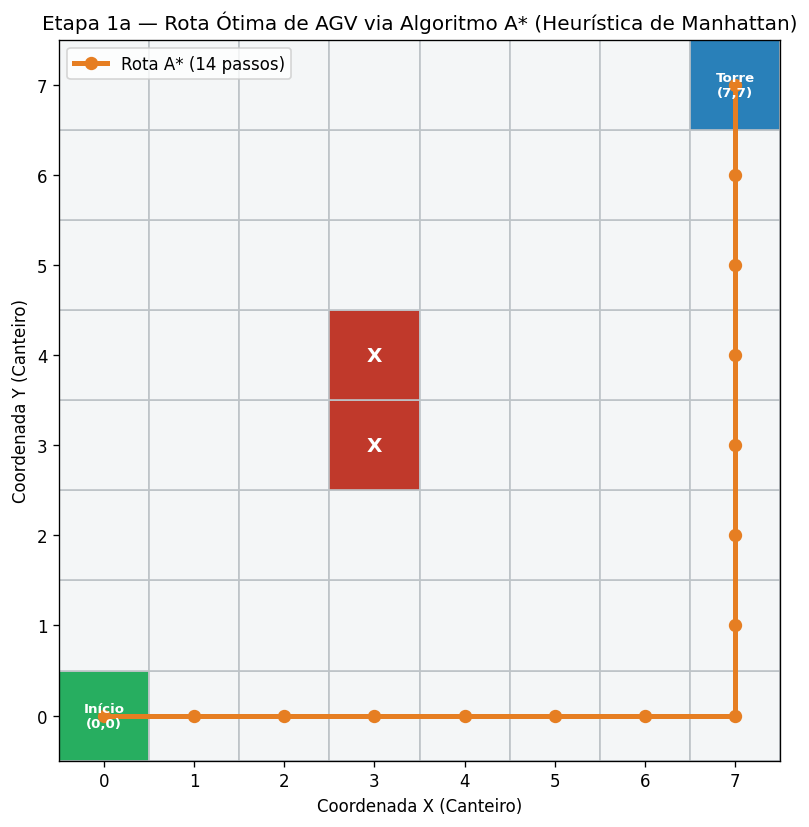

In [2]:
# ==============================================================================
# ETAPA 1a: ROTEAMENTO AUTÔNOMO DE AGVs COM ALGORITMO A* (NETWORKX)
# ==============================================================================

# 1. Criação da malha ortogonal 2D (8x8) representando o canteiro Torre Europarque
G = nx.grid_2d_graph(8, 8)

# 2. Definição dos pontos-chave e obstáculos rígidos (andaimes e escavações)
inicio = (0, 0)       # Almoxarifado Central
destino = (7, 7)      # Torre de Elevação
obstaculos = [(3, 3), (3, 4)]

# Remove os nós bloqueados do grafo
G.remove_nodes_from(obstaculos)

# 3. Definição da heurística admissível: Distância de Manhattan h(n)
def heuristica_manhattan(u, v):
    return abs(u[0] - v[0]) + abs(u[1] - v[1])

# 4. Execução do algoritmo A*
caminho_otimo = nx.astar_path(G, inicio, destino, heuristic=heuristica_manhattan)
custo_total = nx.astar_path_length(G, inicio, destino, heuristic=heuristica_manhattan)

print(f"Origem (Almoxarifado Central): {inicio}")
print(f"Destino (Torre de Elevação):   {destino}")
print(f"Obstáculos removidos:          {obstaculos}")
print(f"Custo total (passos):          {custo_total}")
print(f"Caminho ótimo encontrado:\n{caminho_otimo}")

# Quantos caminhos distintos têm o mesmo custo mínimo? (com e sem obstáculos)
G_livre = nx.grid_2d_graph(8, 8)
n_otimos_livre = len(list(nx.all_shortest_paths(G_livre, inicio, destino)))
n_otimos_obst = len(list(nx.all_shortest_paths(G, inicio, destino)))
print(f"\nh(início) = {heuristica_manhattan(inicio, destino)} passos (limite inferior da heurística)")
print(f"Caminhos ótimos empatados — sem obstáculos: {n_otimos_livre} | com obstáculos: {n_otimos_obst}")

# 5. Visualização gráfica da malha e da rota
fig, ax = plt.subplots(figsize=(7, 7))

# Desenha a grade 8x8
for x in range(8):
    for y in range(8):
        cor = "#F4F6F7"
        if (x, y) in obstaculos:
            cor = "#C0392B"  # Vermelho para obstáculos
        elif (x, y) == inicio:
            cor = "#27AE60"  # Verde para origem
        elif (x, y) == destino:
            cor = "#2980B9"  # Azul para destino
        rect = plt.Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor=cor, edgecolor="#BDC3C7", lw=1)
        ax.add_patch(rect)

# Plota o caminho ótimo
xs = [p[0] for p in caminho_otimo]
ys = [p[1] for p in caminho_otimo]
ax.plot(xs, ys, color="#E67E22", linewidth=3, marker="o", markersize=7, label=f"Rota A* ({custo_total} passos)")

# Anotações de texto nos pontos principais
ax.text(inicio[0], inicio[1], "Início\n(0,0)", ha="center", va="center", color="white", fontweight="bold", fontsize=8)
ax.text(destino[0], destino[1], "Torre\n(7,7)", ha="center", va="center", color="white", fontweight="bold", fontsize=8)
for ox, oy in obstaculos:
    ax.text(ox, oy, "X", ha="center", va="center", color="white", fontweight="bold", fontsize=12)

ax.set_xlim(-0.5, 7.5)
ax.set_ylim(-0.5, 7.5)
ax.set_xticks(range(8))
ax.set_yticks(range(8))
ax.set_xlabel("Coordenada X (Canteiro)")
ax.set_ylabel("Coordenada Y (Canteiro)")
ax.set_title("Etapa 1a — Rota Ótima de AGV via Algoritmo A* (Heurística de Manhattan)")
ax.legend(loc="upper left")
ax.set_aspect("equal")

plt.tight_layout()
plt.savefig("outputs/graficos/etapa1a_astar_rota.png", dpi=300)
plt.show()

**Análise dos resultados (1a)**
- O A* encontrou uma rota de **14 passos**, exatamente o valor da heurística no ponto de partida, h(0,0) = |7−0| + |7−0| = 14. Ou seja, a heurística de Manhattan é **exata** nessa malha (não superestima nem subestima), e o A* expande praticamente só os nós que estão no caminho ótimo.
- Os obstáculos em (3,3) e (3,4) **não aumentam o custo**: eles reduzem de **3.432 para 1.507** o número de caminhos ótimos empatados, mas ainda sobram rotas monotônicas (só para direita e para cima) que os contornam.
- Entre os caminhos empatados, o NetworkX devolveu o que segue pela borda do canteiro. Em uma operação real, esse desempate poderia considerar critérios extras, como manter distância de andaimes e escavações ou evitar áreas de circulação de pessoas.

### 1b — Programação Linear com PuLP (Mini-carregadeiras A, B e C)
O enunciado define apenas a demanda mínima de 450 t/dia. Capacidades, custos, disponibilidade e o limite de 10 equipamentos no pátio são **premissas adotadas pelo grupo** (valores ilustrativos), listadas no início da célula. As variáveis são **inteiras**, já que não é possível alocar fração de equipamento.

Status da Solução: Optimal


,Tipo,Alocadas,Capacidade (t),Custo (R$)
0,Mini-carregadeira A,0,0,0
1,Mini-carregadeira B,4,260,2720
2,Mini-carregadeira C,2,190,1840



Total Transportado: 450 t/dia (Meta: >= 450 t/dia)
Custo Operacional Ótimo: R$ 4.560,00/dia
Custo por tonelada: R$ 10,13/t


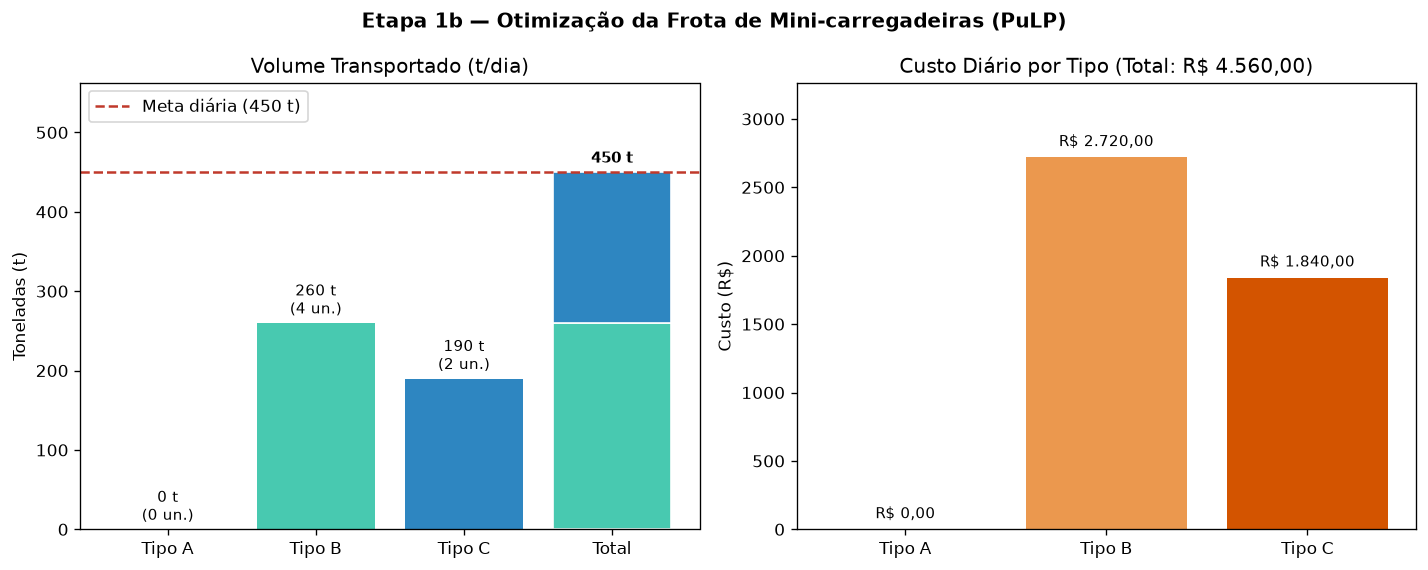

In [ ]:
# ==============================================================================
# ETAPA 1b: ALOCAÇÃO ÓTIMA DE MINI-CARREGADEIRAS COM PULP (PL INTEIRA)
# ==============================================================================

# Premissas operacionais adotadas para o canteiro Torre Europarque:
# - Tipo A (Compacta):        40 t/dia | R$ 450,00/dia | Disponibilidade: 6 unid.
# - Tipo B (Média):           65 t/dia | R$ 680,00/dia | Disponibilidade: 6 unid.
# - Tipo C (Alta Capacidade): 95 t/dia | R$ 920,00/dia | Disponibilidade: 4 unid.
# - Demanda mínima diária:    450 toneladas de argamassa
# - Limite de tráfego no pátio: máximo de 10 equipamentos operando simultaneamente

dados_frota = {
    "A": {"capacidade": 40, "custo": 450, "max_disp": 6},
    "B": {"capacidade": 65, "custo": 680, "max_disp": 6},
    "C": {"capacidade": 95, "custo": 920, "max_disp": 4},
}
demanda_minima = 450

def brl(valor):
    """Formata valores no padrão monetário brasileiro (R$ 1.234,56)."""
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
limite_patio = 10

# 1. Criação do modelo de minimização
modelo = pulp.LpProblem("Alocacao_MiniCarregadeiras_Europarque", pulp.LpMinimize)

# 2. Variáveis de decisão (quantidade inteira de equipamentos alocados)
x = {
    tipo: pulp.LpVariable(f"Qtd_Tipo_{tipo}", lowBound=0, upBound=info["max_disp"], cat="Integer")
    for tipo, info in dados_frota.items()
}

# 3. Função Objetivo: Minimizar o custo operacional diário (R$)
modelo += pulp.lpSum(dados_frota[t]["custo"] * x[t] for t in dados_frota), "Custo_Total_Diario"

# 4. Restrições
# 4.1 Atender no mínimo 450 toneladas/dia
modelo += (
    pulp.lpSum(dados_frota[t]["capacidade"] * x[t] for t in dados_frota) >= demanda_minima,
    "Demanda_Minima_Argamassa"
)
# 4.2 Limite físico de circulação simultânea no canteiro
modelo += (
    pulp.lpSum(x[t] for t in dados_frota) <= limite_patio,
    "Limite_Maximo_Equipamentos"
)

# 5. Resolução
status = modelo.solve(pulp.PULP_CBC_CMD(msg=False))

print(f"Status da Solução: {pulp.LpStatus[status]}")
assert pulp.LpStatus[status] == "Optimal", "O modelo não encontrou solução ótima — revise as premissas."
resumo_pl = []
for t in dados_frota:
    qtd = int(round(x[t].varValue))  # round evita truncar 3.9999 para 3
    ton = qtd * dados_frota[t]["capacidade"]
    custo = qtd * dados_frota[t]["custo"]
    resumo_pl.append({"Tipo": f"Mini-carregadeira {t}", "Alocadas": qtd, "Capacidade (t)": ton, "Custo (R$)": custo})

df_pl = pd.DataFrame(resumo_pl)
display(df_pl)

ton_total = df_pl["Capacidade (t)"].sum()
custo_total_pl = pulp.value(modelo.objective)
print(f"\nTotal Transportado: {ton_total} t/dia (Meta: >= {demanda_minima} t/dia)")
print(f"Custo Operacional Ótimo: {brl(custo_total_pl)}/dia")
print(f"Custo por tonelada: {brl(custo_total_pl / ton_total)}/t")

# 6. Gráfico de alocação e custo
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Gráfico 1: volume por tipo + total empilhado comparado à meta
cores_tipo = ["#5DADE2", "#48C9B0", "#2E86C1"]
rotulos = [f"Tipo {t}" for t in dados_frota]
axes[0].bar(rotulos, df_pl["Capacidade (t)"], color=cores_tipo)
base = 0
for cor, v in zip(cores_tipo, df_pl["Capacidade (t)"]):
    axes[0].bar("Total", v, bottom=base, color=cor, edgecolor="white")
    base += v
axes[0].axhline(demanda_minima, color="#C0392B", linestyle="--", label=f"Meta diária ({demanda_minima} t)")
for i, (v, q) in enumerate(zip(df_pl["Capacidade (t)"], df_pl["Alocadas"])):
    axes[0].text(i, v + 12, f"{v} t\n({q} un.)", ha="center", fontsize=9)
axes[0].text(len(rotulos), ton_total + 12, f"{ton_total} t", ha="center", fontsize=9, fontweight="bold")
axes[0].set_ylim(0, max(ton_total, demanda_minima) * 1.25)
axes[0].set_title("Volume Transportado (t/dia)")
axes[0].set_ylabel("Toneladas (t)")
axes[0].legend(loc="upper left")

# Gráfico 2: custo diário por tipo
axes[1].bar(rotulos, df_pl["Custo (R$)"], color=["#F5B041", "#EB984E", "#D35400"])
for i, v in enumerate(df_pl["Custo (R$)"]):
    axes[1].text(i, v + df_pl["Custo (R$)"].max() * 0.03, brl(v), ha="center", fontsize=9)
axes[1].set_ylim(0, df_pl["Custo (R$)"].max() * 1.2)
axes[1].set_title(f"Custo Diário por Tipo (Total: {brl(custo_total_pl)})")
axes[1].set_ylabel("Custo (R$)")

plt.suptitle("Etapa 1b — Otimização da Frota de Mini-carregadeiras (PuLP)", fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/graficos/etapa1b_pulp_frota.png", dpi=300)
plt.show()

**Análise dos resultados (1b)**
- Solução **ótima**: **4 mini-carregadeiras do tipo B e 2 do tipo C** (nenhuma do tipo A), transportando exatamente **450 t/dia** a um custo de **R$ 4.560,00/dia** (≈ R$ 10,13 por tonelada).
- Custo por tonelada de cada tipo: A = R$ 11,25/t, B = R$ 10,46/t, C = R$ 9,68/t. O tipo C é o mais eficiente, mas usar apenas ele não compensa: 4 unidades do tipo C entregam 380 t, e completar a meta com 2 do tipo A custaria R$ 4.580,00. A combinação B + C atinge a meta **sem sobra de capacidade**, e por isso é a de menor custo.
- As restrições de disponibilidade e de limite do pátio (6 equipamentos de 10 permitidos) **não ficaram ativas**. A restrição que define a solução é a demanda mínima.
- Como os parâmetros são premissas do grupo, o modelo deve ser reexecutado com os custos e capacidades reais da construtora antes de qualquer decisão de contratação.

## Etapa 2 — Otimização de Rotas (VRP) e Simulação de Eventos Discretos

### 2a — Algoritmo Genético para VRP Capacitado com DEAP
Entrega de concreto usinado a **6 blocos de edificação** a partir do Depósito Central, com um **caminhão-betoneira de capacidade máxima de 120 t**. Como a demanda total (270 t) é maior que a capacidade de uma carga, o caminhão faz até 3 viagens, e cada viagem sai do depósito, atende blocos e volta para recarregar. O enunciado define os 6 blocos e a capacidade; as posições na malha, as demandas e o limite de 3 viagens são **premissas ilustrativas do grupo**, listadas no início da célula. As distâncias são os menores caminhos na malha 8x8 da Etapa 1, com os obstáculos em (3,3) e (3,4).

O cromossomo é uma **permutação** dos 6 blocos e de 2 separadores de viagem, o que permite usar `cxOrdered` (cruzamento ordenado) e `mutShuffleIndexes` (mutação por troca de posições), com seleção por torneio, sem gerar indivíduos inválidos. O fitness é a distância total mais **20 passos por tonelada acima de 120 t** em cada viagem. Como a carga não é uma restrição rígida, o GA pode visitar soluções inviáveis, mas elas são penalizadas e tendem a desaparecer.

,Viagem,Rota,Carga (t),Excesso (t),Distância (passos)
0,1,Depósito -> P2 -> Depósito,55,0,8
1,2,Depósito -> P6 -> P4 -> Depósito,110,0,26
2,3,Depósito -> P1 -> P5 -> P3 -> Depósito,105,0,22



Melhor fitness (GA): 56
Distância total: 56 passos | Excesso de carga: 0 t | Solução VIÁVEL


,Método,Fitness / distância
0,Ótimo exato (programação dinâmica),56.0
1,GA - execução principal (SEED),56.0
2,GA - média de 10 execuções,56.2
3,GA - pior das 10 execuções,58.0
4,Busca aleatória (mesmo nº de avaliações),56.0



Gap do GA (execução principal) em relação ao ótimo: 0.0%
Execuções do GA que atingiram o ótimo: 9 de 10


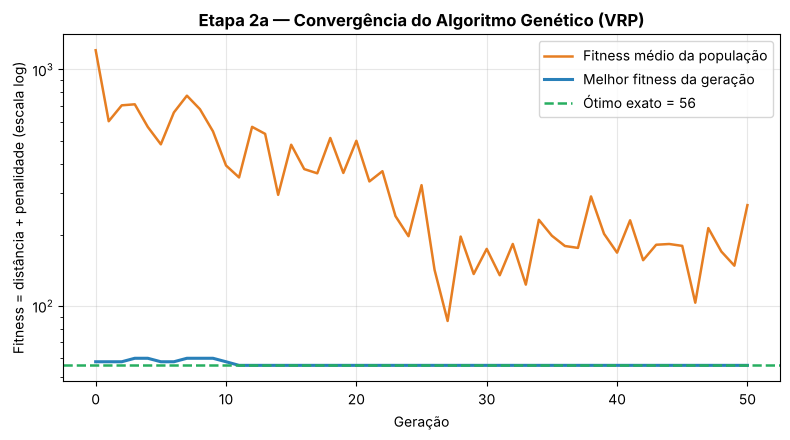

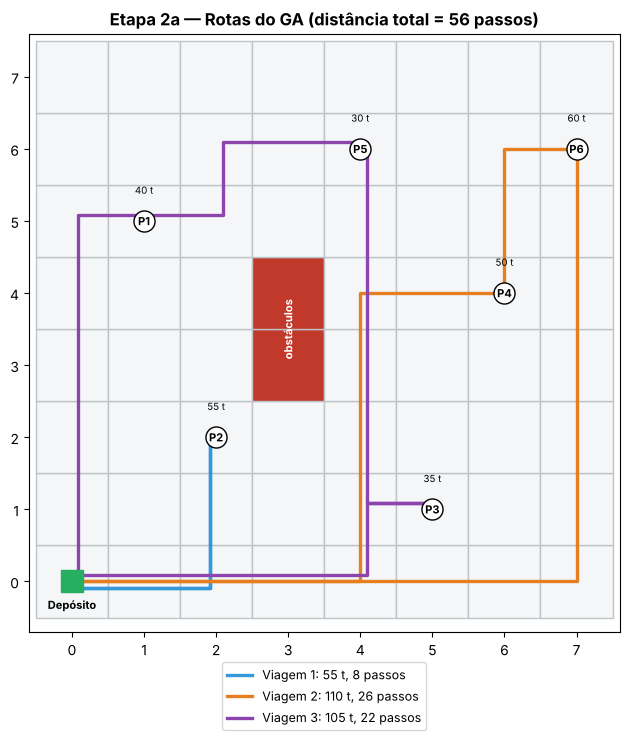

In [ ]:
# ==============================================================================
# ETAPA 2a - ALGORITMO GENÉTICO PARA VRP COM DEAP
# ==============================================================================

# Reinicia as sementes (outras células alteram o estado do gerador aleatório)
random.seed(SEED)
np.random.seed(SEED)

# ------------------------------------------------------------------------------
# 1. Premissas do problema
# ------------------------------------------------------------------------------
# Do enunciado: entrega de concreto usinado a 6 blocos de edificação, a partir do
# Depósito Central, com caminhão-betoneira de capacidade máxima de 120 t.
# Premissas do grupo (ilustrativas): posição e demanda de cada bloco, e o número de
# viagens do caminhão-betoneira (cada viagem sai do depósito, atende blocos e volta
# para recarregar). As distâncias são os menores caminhos na malha 8x8 da Etapa 1,
# já com os obstáculos em (3,3) e (3,4) (a "distância" é o número de passos).
CAPACIDADE   = 120          # capacidade do caminhão-betoneira (t)
NUM_VEICULOS = 3            # viagens disponíveis (3 x 120 t = 360 t para 270 t de demanda)
DEPOSITO     = (0, 0)       # Depósito Central
PENALIDADE   = 20           # custo (em passos) de cada tonelada acima de 120 t

entregas = [  # (bloco, posição na malha, demanda de concreto em toneladas)
    ("Bloco 1", (1, 5), 40),
    ("Bloco 2", (2, 2), 55),
    ("Bloco 3", (5, 1), 35),
    ("Bloco 4", (6, 4), 50),
    ("Bloco 5", (4, 6), 30),
    ("Bloco 6", (7, 6), 60),
]
N = len(entregas)                       # número de blocos
demandas = [d for _, _, d in entregas]

# Matriz de distâncias (índice 0 = almoxarifado; cliente i -> índice i+1)
G_vrp = nx.grid_2d_graph(8, 8)
G_vrp.remove_nodes_from([(3, 3), (3, 4)])
nos = [DEPOSITO] + [pos for _, pos, _ in entregas]
dist = np.zeros((N + 1, N + 1), dtype=int)
for i, u in enumerate(nos):
    caminhos = nx.single_source_shortest_path_length(G_vrp, u)
    for j, v in enumerate(nos):
        dist[i, j] = caminhos[v]

# ------------------------------------------------------------------------------
# 2. Representação do cromossomo e função de aptidão (fitness)
# ------------------------------------------------------------------------------
# Cromossomo = PERMUTAÇÃO de 0..N+K-2. Os valores 0..N-1 são os blocos e os
# K-1 valores restantes (N, N+1, ...) são "separadores" que marcam o fim de uma
# rota. Assim, cxOrdered e mutShuffleIndexes sempre geram permutações válidas.
TAM_CROMOSSOMO = N + NUM_VEICULOS - 1

def decodificar(individuo):
    """Converte a permutação em uma lista de rotas (uma lista de blocos por viagem)."""
    rotas, atual = [], []
    for gene in individuo:
        if gene >= N:               # separador: fecha a rota atual
            rotas.append(atual)
            atual = []
        else:
            atual.append(gene)
    rotas.append(atual)
    return rotas

def distancia_rota(rota):
    if not rota:
        return 0
    idx = [0] + [c + 1 for c in rota] + [0]          # depósito -> blocos -> depósito
    return int(sum(dist[a, b] for a, b in zip(idx, idx[1:])))

def carga_rota(rota):
    return sum(demandas[c] for c in rota)

def avaliar(individuo):
    """Fitness (minimizar) = distância total + PENALIDADE x excesso de carga acima de 120 t."""
    rotas = decodificar(individuo)
    distancia_total = sum(distancia_rota(r) for r in rotas)
    excesso = sum(max(0, carga_rota(r) - CAPACIDADE) for r in rotas)
    return (distancia_total + PENALIDADE * excesso,)

# ------------------------------------------------------------------------------
# 3. Configuração do DEAP: cxOrdered, mutShuffleIndexes e seleção por torneio
# ------------------------------------------------------------------------------
if not hasattr(creator, "FitnessMin"):      # evita aviso ao reexecutar a célula
    creator.create("FitnessMin", base.Fitness, weights=(-1.0,))     # minimização
    creator.create("Individual", list, fitness=creator.FitnessMin)

toolbox = base.Toolbox()
toolbox.register("permutacao", random.sample, range(TAM_CROMOSSOMO), TAM_CROMOSSOMO)
toolbox.register("individuo", tools.initIterate, creator.Individual, toolbox.permutacao)
toolbox.register("populacao", tools.initRepeat, list, toolbox.individuo)
toolbox.register("evaluate", avaliar)
toolbox.register("mate", tools.cxOrdered)                                   # cruzamento ordenado (OX)
toolbox.register("mutate", tools.mutShuffleIndexes, indpb=0.1)              # mutação por troca de posições
toolbox.register("select", tools.selTournament, tournsize=3)                # torneio de tamanho 3

TAM_POP, N_GERACOES, CXPB, MUTPB = 60, 50, 0.8, 0.3

def executar_ga(seed):
    """Executa uma rodada completa do GA e devolve o melhor indivíduo e o histórico por geração."""
    random.seed(seed)
    pop = toolbox.populacao(n=TAM_POP)
    hof = tools.HallOfFame(1)
    stats = tools.Statistics(lambda ind: ind.fitness.values[0])
    stats.register("min", np.min)
    stats.register("med", np.mean)
    _, log = algorithms.eaSimple(pop, toolbox, cxpb=CXPB, mutpb=MUTPB,
                                 ngen=N_GERACOES, stats=stats, halloffame=hof, verbose=False)
    return hof[0], log

# ------------------------------------------------------------------------------
# 4. Execução principal (semente global) e resultado
# ------------------------------------------------------------------------------
melhor, log = executar_ga(SEED)
rotas_ga = decodificar(melhor)

linhas = []
for k, rota in enumerate(rotas_ga, start=1):
    linhas.append({
        "Viagem": k,
        "Rota": "Depósito -> " + " -> ".join(f"P{c + 1}" for c in rota) + " -> Depósito" if rota else "(viagem não utilizada)",
        "Carga (t)": carga_rota(rota),
        "Excesso (t)": max(0, carga_rota(rota) - CAPACIDADE),
        "Distância (passos)": distancia_rota(rota),
    })
df_rotas = pd.DataFrame(linhas)
display(df_rotas)

dist_ga = sum(distancia_rota(r) for r in rotas_ga)
excesso_ga = sum(max(0, carga_rota(r) - CAPACIDADE) for r in rotas_ga)
print(f"\nMelhor fitness (GA): {melhor.fitness.values[0]:.0f}")
print(f"Distância total: {dist_ga} passos | Excesso de carga: {excesso_ga} t | "
      f"Solução {'VIÁVEL' if excesso_ga == 0 else 'INVIÁVEL'}")
df_rotas.to_csv("outputs/tabelas/etapa2a_ga_rotas.csv", index=False)

# ------------------------------------------------------------------------------
# 5. Validação: ótimo exato (programação dinâmica) e busca aleatória com o mesmo orçamento
# ------------------------------------------------------------------------------
# Com apenas 6 blocos é possível calcular o ótimo exato (Held-Karp para a melhor
# ordem de cada subconjunto + partição dos blocos em até 3 viagens). Serve para
# medir a qualidade da solução do GA.
INF = 10**9
tsp = np.full((1 << N, N), INF)
for i in range(N):
    tsp[1 << i, i] = dist[0, i + 1]
for mask in range(1, 1 << N):
    for ult in range(N):
        if tsp[mask, ult] >= INF:
            continue
        for prox in range(N):
            if not (mask >> prox) & 1:
                nova = mask | (1 << prox)
                tsp[nova, prox] = min(tsp[nova, prox], tsp[mask, ult] + dist[ult + 1, prox + 1])
custo_sub = np.full(1 << N, INF)
custo_sub[0] = 0
carga_sub = np.zeros(1 << N, dtype=int)
for mask in range(1, 1 << N):
    carga_sub[mask] = sum(demandas[i] for i in range(N) if (mask >> i) & 1)
    custo_sub[mask] = min(tsp[mask, u] + dist[u + 1, 0] for u in range(N) if (mask >> u) & 1)

melhor_k = np.full(1 << N, INF)     # custo mínimo para atender o conjunto com até k viagens
melhor_k[0] = 0
for _ in range(NUM_VEICULOS):
    novo = melhor_k.copy()
    for mask in range(1, 1 << N):
        sub = mask
        while sub:                  # percorre todos os subconjuntos de mask
            if carga_sub[sub] <= CAPACIDADE:
                novo[mask] = min(novo[mask], custo_sub[sub] + melhor_k[mask ^ sub])
            sub = (sub - 1) & mask
    melhor_k = novo
otimo = int(melhor_k[(1 << N) - 1])

# Busca aleatória com o mesmo número de avaliações do GA (referência de "sem inteligência")
n_aval = TAM_POP * (N_GERACOES + 1)
random.seed(SEED)
melhor_aleatorio = min(avaliar(random.sample(range(TAM_CROMOSSOMO), TAM_CROMOSSOMO))[0]
                       for _ in range(n_aval))

# Robustez: 10 execuções independentes do GA
resultados_ga = []
for s in range(10):
    ind, _ = executar_ga(SEED + s)
    resultados_ga.append(ind.fitness.values[0])
resultados_ga = np.array(resultados_ga)

tabela_val = pd.DataFrame({
    "Método": ["Ótimo exato (programação dinâmica)", "GA - execução principal (SEED)",
               "GA - média de 10 execuções", "GA - pior das 10 execuções",
               "Busca aleatória (mesmo nº de avaliações)"],
    "Fitness / distância": [otimo, melhor.fitness.values[0], resultados_ga.mean(),
                            resultados_ga.max(), melhor_aleatorio],
})
display(tabela_val.round(1))
tabela_val.to_csv("outputs/tabelas/etapa2a_ga_validacao.csv", index=False)
print(f"\nGap do GA (execução principal) em relação ao ótimo: "
      f"{(melhor.fitness.values[0] - otimo) / otimo * 100:.1f}%")
print(f"Execuções do GA que atingiram o ótimo: {(resultados_ga == otimo).sum()} de 10")

# Restaura a semente global (executar_ga e a busca aleatória alteram o gerador)
random.seed(SEED)
np.random.seed(SEED)

# ------------------------------------------------------------------------------
# 6. Gráficos: convergência e rotas na malha do canteiro
# ------------------------------------------------------------------------------
geracoes = log.select("gen")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(geracoes, log.select("med"), color="#E67E22", lw=1.8, label="Fitness médio da população")
ax.plot(geracoes, log.select("min"), color="#2980B9", lw=2.2, label="Melhor fitness da geração")
ax.axhline(otimo, color="#27AE60", ls="--", lw=1.8, label=f"Ótimo exato = {otimo}")
ax.set_yscale("log")
ax.set_xlabel("Geração")
ax.set_ylabel("Fitness = distância + penalidade (escala log)")
ax.set_title("Etapa 2a — Convergência do Algoritmo Genético (VRP)", fontweight="bold")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/graficos/etapa2a_ga_convergencia.png", dpi=300)
plt.show()

cores = ["#3498DB", "#E67E22", "#8E44AD"]
fig, ax = plt.subplots(figsize=(7.5, 7.5))
for x in range(8):
    for y in range(8):
        cor = "#C0392B" if (x, y) in [(3, 3), (3, 4)] else "#F4F6F7"
        ax.add_patch(plt.Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor=cor, edgecolor="#BDC3C7", lw=1))
for k, rota in enumerate(rotas_ga):
    if not rota:
        continue
    seq = [DEPOSITO] + [entregas[c][1] for c in rota] + [DEPOSITO]
    trajeto = []
    for a, b in zip(seq, seq[1:]):
        trajeto += nx.shortest_path(G_vrp, a, b)[:-1]
    trajeto.append(DEPOSITO)
    desloc = (k - 1) * 0.09                      # pequeno deslocamento para as rotas não se sobreporem
    ax.plot([p[0] + desloc for p in trajeto], [p[1] + desloc for p in trajeto], color=cores[k], lw=2.4,
            label=f"Viagem {k + 1}: {carga_rota(rota)} t, {distancia_rota(rota)} passos")
ax.scatter(*DEPOSITO, s=260, marker="s", color="#27AE60", zorder=5)
ax.text(DEPOSITO[0], DEPOSITO[1] - 0.38, "Depósito", ha="center", fontsize=8, fontweight="bold")
for i, (_, pos, d) in enumerate(entregas):
    ax.scatter(*pos, s=230, color="white", edgecolor="black", zorder=5)
    ax.text(pos[0], pos[1], f"P{i + 1}", ha="center", va="center", fontsize=8, fontweight="bold", zorder=6)
    ax.text(pos[0], pos[1] + 0.38, f"{d} t", ha="center", fontsize=7, zorder=6)
ax.text(3, 3.5, "obstáculos", ha="center", va="center", fontsize=8, color="white", fontweight="bold", rotation=90)
ax.set_xlim(-0.6, 7.6)
ax.set_ylim(-0.7, 7.6)
ax.set_aspect("equal")
ax.set_title(f"Etapa 2a — Rotas do GA (distância total = {dist_ga} passos)", fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=1, fontsize=9)
plt.tight_layout()
plt.savefig("outputs/graficos/etapa2a_ga_rotas.png", dpi=300)
plt.show()

**Análise dos resultados (2a)**
- O GA encontrou três viagens **viáveis** (nenhuma acima de 120 t) com **56 passos** no total, valor igual ao **ótimo exato** calculado por programação dinâmica (gap de 0,0%). As cargas foram de 55 t, 110 t e 105 t. Como 270 t > 2 × 120 t, são necessárias no mínimo 3 viagens.
- A convergência foi rápida: o melhor fitness caiu de **58** (geração 0) para **56** na geração 11 e ficou estável. O fitness médio caiu de ≈ 1.206 para ≈ 267 e se estabilizou: ele continua alto porque a população mantém indivíduos inviáveis (penalizados) gerados pelo cruzamento e pela mutação.
- Em 10 execuções independentes, o GA atingiu o ótimo em **9** e ficou em 58 passos em 1 (média de 56,2). A busca aleatória com o mesmo número de avaliações (3.060) também chegou a 56, ou seja, **nesta instância de 6 blocos o GA não mostra vantagem sobre a busca aleatória**: o espaço de busca é pequeno (8! = 40.320 permutações). A vantagem do GA aparece quando o número de blocos cresce, pois o espaço cresce de forma fatorial.
- As viagens 1 e 2 são idas e voltas diretas, sem desvio (8 = 2 × 4 e 26 = 2 × 13 passos). A viagem 3 atende três blocos em 22 passos.
- **Limitações:** as posições, as demandas e o limite de 3 viagens são premissas do grupo. O ótimo exato só é viável porque a instância é pequena. Os parâmetros do GA (população 60, 50 gerações, cruzamento 0,8, mutação 0,3) não passaram por calibração sistemática.

### 2b — Simulação de Concretagem com SimPy (Betoneira M1 → Bomba M2)
Linha em série com dois recursos de capacidade 1: a **Betoneira M1** (preparo, média de 5 min) e a **Bomba M2** (bombeamento, média de 7 min), ambos com tempos exponenciais, durante **300 min**. O enunciado não define o ritmo de chegada das demandas de carga: o grupo adotou **intervalo exponencial com média de 8 min**, maior que o tempo do recurso mais lento, para que o sistema seja estável. São executadas **30 réplicas** independentes, e os resultados são reportados como média ± desvio padrão.

,Média (30 réplicas),Desvio Padrão
Cargas_Processadas,34.00,4.50
Fila_Media_M1_min,7.22,5.50
Fila_Media_M2_min,15.26,10.48
Utilizacao_M1_%,65.10,12.65
Utilizacao_M2_%,76.50,12.67



Utilização média: M1 = 65.1% | M2 = 76.5%
Fila média:       M1 = 7.2 min | M2 = 15.3 min
>>> GARGALO IDENTIFICADO NA LINHA: Bomba de Concreto M2


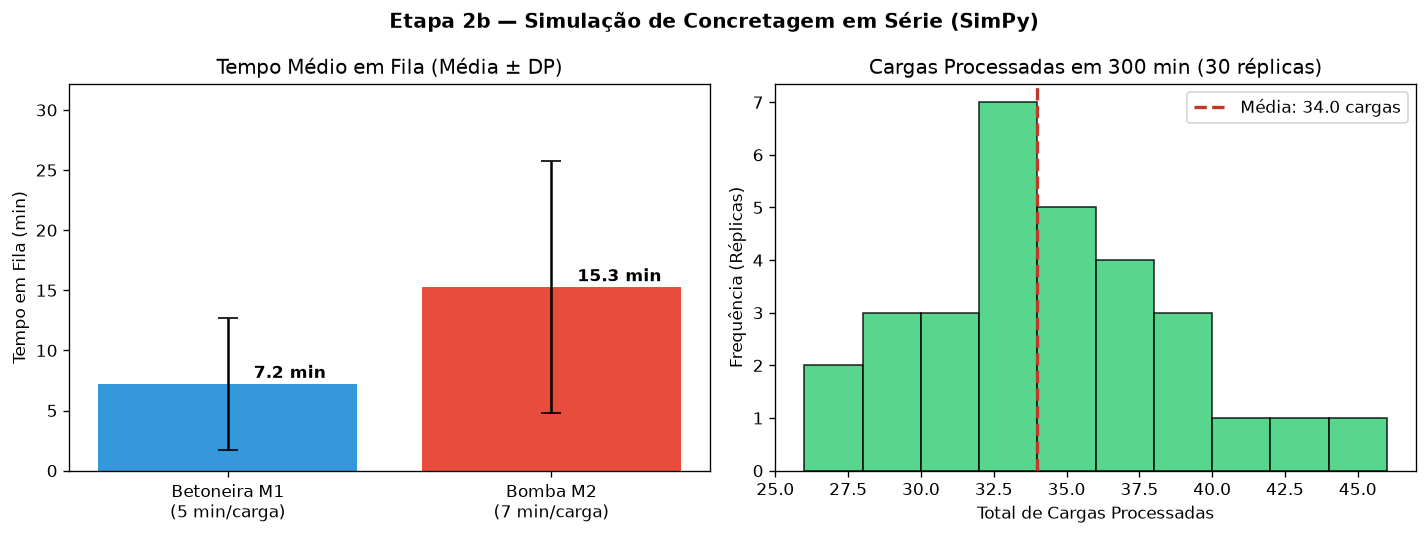

In [ ]:
# ==============================================================================
# ETAPA 2b: SIMULAÇÃO DE CONCRETAGEM EM SÉRIE COM SIMPY (M1 -> M2)
# ==============================================================================

TEMPO_SIMULACAO = 300.0   # minutos (5 horas de operação contínua)
MEDIA_CHEGADA   = 8.0     # intervalo médio entre demandas de carga (min)
                          # premissa do grupo: maior que o serviço mais lento (7 min),
                          # para o sistema ser estável (com 5 min, a M1 opera com ρ = 1
                          # e as duas filas crescem sem limite, mascarando o gargalo)
MEDIA_M1        = 5.0     # tempo médio de preparo na Betoneira M1 (min)
MEDIA_M2        = 7.0     # tempo médio de bombeamento na Bomba M2 (min)
NUM_REPLICAS    = 30      # número de réplicas independentes

def executar_replica(seed):
    random.seed(seed)
    env = simpy.Environment()
    m1 = simpy.Resource(env, capacity=1)
    m2 = simpy.Resource(env, capacity=1)

    filas_m1, filas_m2 = [], []
    tempo_uso_m1, tempo_uso_m2 = 0.0, 0.0
    cargas_processadas = 0

    def processo_carga(env):
        nonlocal tempo_uso_m1, tempo_uso_m2, cargas_processadas

        # --- Estágio 1: Betoneira M1 ---
        chegada_m1 = env.now
        with m1.request() as req1:
            yield req1
            filas_m1.append(env.now - chegada_m1)
            duracao_m1 = random.expovariate(1.0 / MEDIA_M1)
            yield env.timeout(duracao_m1)
            tempo_uso_m1 += duracao_m1

        # --- Estágio 2: Bomba de Concreto M2 ---
        chegada_m2 = env.now
        with m2.request() as req2:
            yield req2
            filas_m2.append(env.now - chegada_m2)
            duracao_m2 = random.expovariate(1.0 / MEDIA_M2)
            yield env.timeout(duracao_m2)
            tempo_uso_m2 += duracao_m2

        cargas_processadas += 1

    def gerador_cargas(env):
        while True:
            env.process(processo_carga(env))
            yield env.timeout(random.expovariate(1.0 / MEDIA_CHEGADA))

    env.process(gerador_cargas(env))
    env.run(until=TEMPO_SIMULACAO)

    return {
        "Replica": seed - SEED + 1,
        "Cargas_Processadas": cargas_processadas,
        "Fila_Media_M1_min": np.mean(filas_m1) if filas_m1 else 0.0,
        "Fila_Media_M2_min": np.mean(filas_m2) if filas_m2 else 0.0,
        "Utilizacao_M1_%": min(100.0, (tempo_uso_m1 / TEMPO_SIMULACAO) * 100),
        "Utilizacao_M2_%": min(100.0, (tempo_uso_m2 / TEMPO_SIMULACAO) * 100),
    }

# Executa as 30 réplicas com seeds reprodutíveis (SEED, SEED+1, ...)
resultados_simpy = [executar_replica(SEED + i) for i in range(NUM_REPLICAS)]
df_simpy = pd.DataFrame(resultados_simpy)

# Estatísticas consolidadas
resumo_simpy = df_simpy.drop(columns=["Replica"]).agg(["mean", "std"]).T
resumo_simpy.columns = ["Média (30 réplicas)", "Desvio Padrão"]
display(resumo_simpy.round(2))

# Gargalo: recurso com maior utilização média, confirmado pela maior fila média
util_m1, util_m2 = df_simpy["Utilizacao_M1_%"].mean(), df_simpy["Utilizacao_M2_%"].mean()
fila_m1, fila_m2 = df_simpy["Fila_Media_M1_min"].mean(), df_simpy["Fila_Media_M2_min"].mean()
gargalo = "Bomba de Concreto M2" if util_m2 > util_m1 else "Betoneira M1"
confirmado = (util_m2 > util_m1) == (fila_m2 > fila_m1)
print(f"\nUtilização média: M1 = {util_m1:.1f}% | M2 = {util_m2:.1f}%")
print(f"Fila média:       M1 = {fila_m1:.1f} min | M2 = {fila_m2:.1f} min")
print(f">>> GARGALO IDENTIFICADO NA LINHA: {gargalo}"
      + ("" if confirmado else " (atenção: fila e utilização apontam recursos diferentes)"))

# Restaura a semente global (executar_replica altera o estado do gerador)
random.seed(SEED)

# Gráficos comparativos
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Gráfico 1: Comparação do Tempo Médio em Fila (M1 vs M2)
medias_fila = [df_simpy["Fila_Media_M1_min"].mean(), df_simpy["Fila_Media_M2_min"].mean()]
stds_fila   = [df_simpy["Fila_Media_M1_min"].std(),  df_simpy["Fila_Media_M2_min"].std()]
axes[0].bar(["Betoneira M1\n(5 min/carga)", "Bomba M2\n(7 min/carga)"], medias_fila,
            yerr=stds_fila, capsize=6, color=["#3498DB", "#E74C3C"])
axes[0].set_title("Tempo Médio em Fila (Média ± DP)")
axes[0].set_ylim(0, max(m + d for m, d in zip(medias_fila, stds_fila)) * 1.25)
axes[0].set_ylabel("Tempo em Fila (min)")
for i, v in enumerate(medias_fila):
    axes[0].text(i + 0.08, v + 0.5, f"{v:.1f} min", ha="left", fontweight="bold")

# Gráfico 2: Distribuição de Cargas Processadas nas 30 réplicas
axes[1].hist(df_simpy["Cargas_Processadas"], bins=10, color="#2ECC71", edgecolor="black", alpha=0.8)
media_cargas = df_simpy["Cargas_Processadas"].mean()
axes[1].axvline(media_cargas, color="#C0392B", linestyle="--", lw=2, label=f"Média: {media_cargas:.1f} cargas")
axes[1].set_title(f"Cargas Processadas em {int(TEMPO_SIMULACAO)} min ({NUM_REPLICAS} réplicas)")
axes[1].set_xlabel("Total de Cargas Processadas")
axes[1].set_ylabel("Frequência (Réplicas)")
axes[1].legend()

plt.suptitle("Etapa 2b — Simulação de Concretagem em Série (SimPy)", fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/graficos/etapa2b_simpy_gargalo.png", dpi=300)
plt.show()

**Análise dos resultados (2b)**
- Em 300 min, a linha processou em média **34,0 ± 4,5 cargas** nas 30 réplicas.
- A **Bomba de Concreto M2** é o **gargalo**: ela tem a maior utilização (**76,5%** contra **65,1%** da Betoneira M1) e o maior tempo médio em fila (**15,3 min** contra **7,2 min**). Isso é coerente com a teoria: a M2 é o recurso mais lento (7 min contra 5 min), e a capacidade máxima dela, de ≈ 300/7 ≈ 43 cargas, limita a vazão da linha inteira.
- O desvio padrão elevado mostra a alta variabilidade causada pelos tempos exponenciais. Por isso foram usadas várias réplicas, em vez de uma execução única.
- **Recomendação:** aumentar a capacidade da etapa de bombeamento (uma segunda bomba ou redução do tempo de bombeamento) traz mais ganho do que investir na betoneira. Melhorar a M1 só aumentaria a fila na frente da M2.
- **Limitações:** a média de fila considera apenas as cargas que chegaram a ser atendidas. Cargas ainda esperando no minuto 300 não entram na conta, o que subestima levemente a fila da M2. A utilização também conta apenas os serviços concluídos dentro do horizonte.

## Etapa 3 — Ontologia RDF/OWL e Consultas SPARQL

In [ ]:
# ==============================================================================
# ETAPA 3 - ONTOLOGIA RDF/OWL E CONSULTAS SPARQL
# ==============================================================================

## Etapa 4 — Rede Neural MLP do Zero em NumPy (Forward Pass)

In [ ]:
# ==============================================================================
# ETAPA 4 - REDE NEURAL MLP DO ZERO EM NUMPY
# ==============================================================================

# Reinicia a semente para pesos reprodutíveis
np.random.seed(SEED)

## Etapa 5 — Sistema de Inferência Fuzzy (Mamdani e Sugeno)


In [ ]:
# ==============================================================================
# ETAPA 5 - SISTEMA DE INFERÊNCIA FUZZY
# ==============================================================================